# Walkthrough: ORB and the Overnight Drift in the Nifty 50

This notebook rebuilds every number in the [README](../README.md), one section at a time, from the tables in `results/`.
**It needs no market data**, so anyone can run it top to bottom.

The tables in `results/` were produced by `src/build_results.py` from one-minute Nifty 50 index candles from the FYERS broker. That data is not included.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import orb_overnight as orb

R = ROOT / 'results'
LAKH = orb.QUANTITY / 1e5          # index points -> INR lakh at 260 units
SYSTEM = 'System (exit 09:45 next day)'
pd.options.display.float_format = '{:,.2f}'.format

trades = pd.read_csv(R / 'trades.csv', parse_dates=['entry_time', 'exit_time'])
daily = pd.read_csv(R / 'daily.csv', parse_dates=['date'])
nights = pd.read_csv(R / 'nights.csv', parse_dates=['date', 'next_date'])
clock_daily = pd.read_csv(R / 'exit_clock_daily.csv', parse_dates=['date'])
clock_parts = pd.read_csv(R / 'exit_clock_attribution.csv')
index = pd.read_csv(R / 'index_overnight_daytime.csv', parse_dates=['date'])


def show(figure):
    display(Image(filename=str(ROOT / 'figures' / f'{figure}-light.png'), width=760))


def sharpe(points):
    return points.mean() / points.std(ddof=1) * np.sqrt(252)


def max_drawdown(points):
    equity = np.r_[0, np.cumsum(points)]
    return (np.maximum.accumulate(equity) - equity).max()

## 1. The system

The account figures for the system as designed: exit at 09:45 the next morning. `orb.metrics` uses daily P&L, marked at each close, for Sharpe and drawdown, and the trade list for profit factor.

In [2]:
masks = {'In-sample': daily.period == 'IS', 'Out-of-sample': daily.period == 'OOS', 'Full history': daily.period.notna()}
trade_masks = {'In-sample': trades.period == 'IS', 'Out-of-sample': trades.period == 'OOS', 'Full history': trades.period.notna()}
system = pd.DataFrame({name: orb.metrics(daily.loc[m, SYSTEM], trades.loc[trade_masks[name], 'net_points'])
                       for name, m in masks.items()})
system.loc[['trades', 'net_lakh', 'profit_factor', 'sharpe', 'max_dd_lakh']]

,In-sample,Out-of-sample,Full history
trades,700.00,487.00,"1,187.00"
net_lakh,29.10,15.39,44.50
profit_factor,1.43,1.25,1.34
sharpe,1.66,1.01,1.35
max_dd_lakh,3.82,3.80,3.82


In [3]:
equity = 10 + daily[SYSTEM].cumsum() * LAKH
drawdown_pct = ((equity.cummax() - equity) / equity.cummax()).max() * 100
print(f'Ending equity: INR {equity.iloc[-1]:.2f} lakh; largest drawdown {drawdown_pct:.1f}% of the running peak')
print('Held overnight:', int(trades.overnight.sum()), 'of', len(trades), 'trades')
trades.reason.value_counts()

Ending equity: INR 54.50 lakh; largest drawdown 18.6% of the running peak
Held overnight: 1024 of 1187 trades


reason
scheduled    919
stop         220
target        48
Name: count, dtype: int64

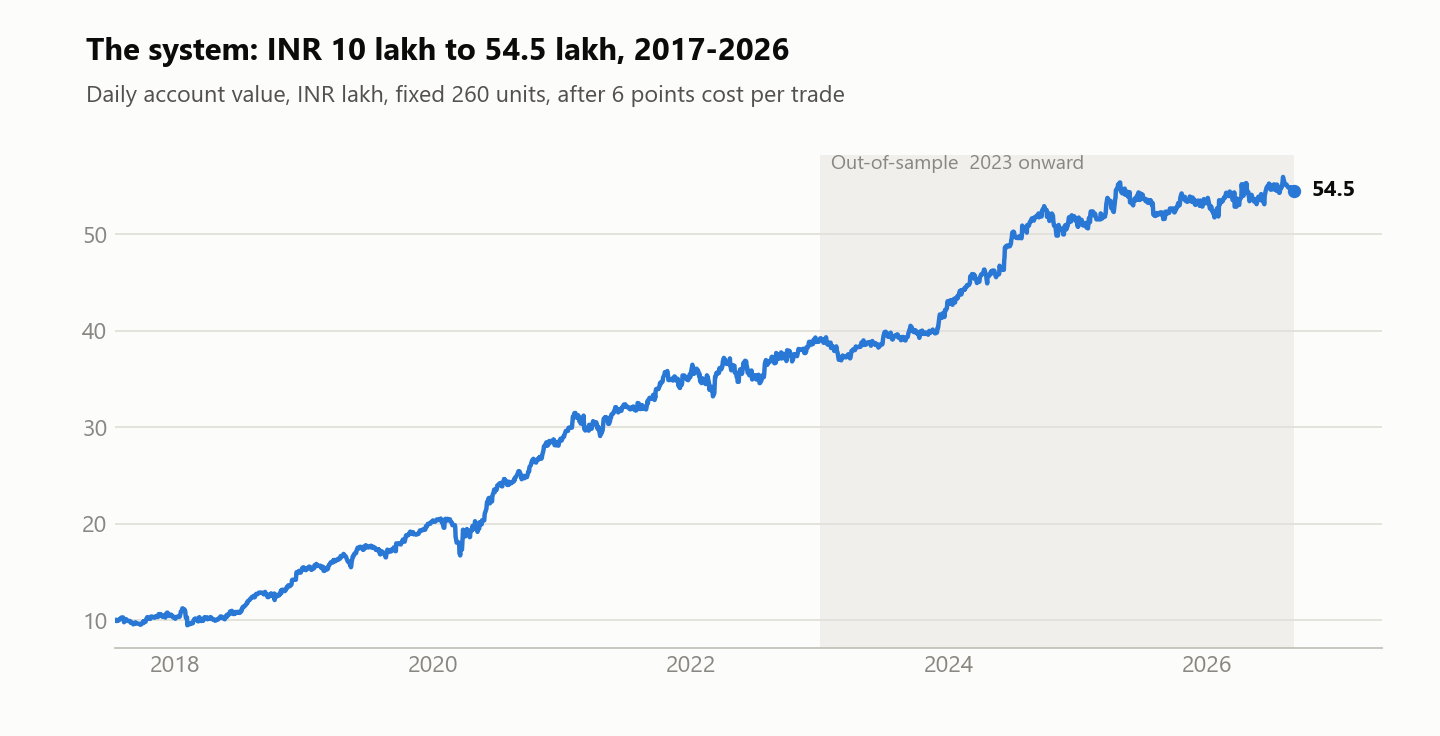

In [4]:
show('1-system-equity')

## 2. Where the profit comes from

Every trade is split into entry day, overnight gap, target cap at the open, next morning and costs. The five parts add up exactly to each trade's net result.

In [5]:
parts = ['entry_day', 'overnight_gap', 'opening_fill_adjustment', 'next_morning', 'costs']
assert np.allclose(trades[parts].sum(axis=1), trades.net_points)
attribution = trades.groupby('period')[parts + ['net_points']].sum() * LAKH
attribution.loc['Full'] = attribution.sum()
attribution

,entry_day,overnight_gap,opening_fill_adjustment,next_morning,costs,net_points
period,,,,,,
IS,10.73,35.88,-1.53,-5.06,-10.92,29.10
OOS,2.86,34.01,-4.14,-9.75,-7.60,15.39
Full,13.59,69.89,-5.66,-14.81,-18.52,44.50


In [6]:
# Without the gap: the entry-day move less all costs
(attribution.entry_day + attribution.costs).rename('entry day minus costs, INR lakh')

period
IS     -0.19
OOS    -4.73
Full   -4.92
Name: entry day minus costs, INR lakh, dtype: float64

In [7]:
# The overnight gap component, booked on the morning it happened, by year
gap_by_year = daily.groupby(daily.date.dt.year).overnight_gap.sum() * LAKH
print('Every year positive:', bool((gap_by_year > 0).all()))
gap_by_year

Every year positive: True


date
2017    2.16
2018    4.88
2019    5.56
2020   10.05
2021    8.00
2022    5.23
2023    9.05
2024   10.64
2025    7.44
2026    6.87
Name: overnight_gap, dtype: float64

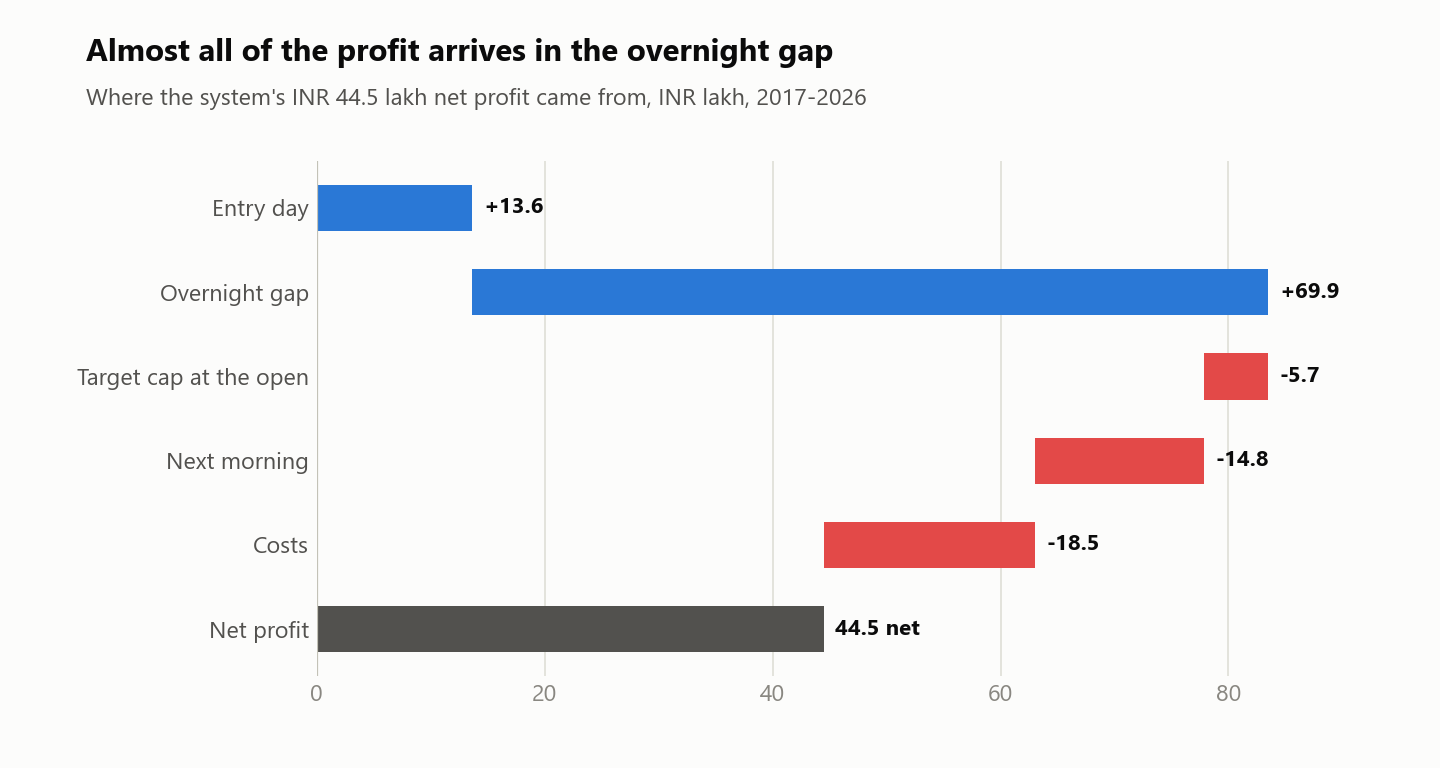

In [8]:
show('2-profit-attribution')

## 3. Remove the night

The same entries, stops and targets, but closed at 15:25 the same day.

In [9]:
SAME_DAY = 'Same signals, exit 15:25 same day'
night_test = pd.DataFrame({p: {'held overnight, INR lakh': daily.loc[daily.period == p, SYSTEM].sum() * LAKH,
                               'held overnight, Sharpe': sharpe(daily.loc[daily.period == p, SYSTEM]),
                               'closed 15:25, INR lakh': daily.loc[daily.period == p, SAME_DAY].sum() * LAKH,
                               'closed 15:25, Sharpe': sharpe(daily.loc[daily.period == p, SAME_DAY])}
                           for p in ['IS', 'OOS']})
night_test

,IS,OOS
"held overnight, INR lakh",29.10,15.39
"held overnight, Sharpe",1.66,1.01
"closed 15:25, INR lakh",-0.38,-3.52
"closed 15:25, Sharpe",-0.03,-0.32


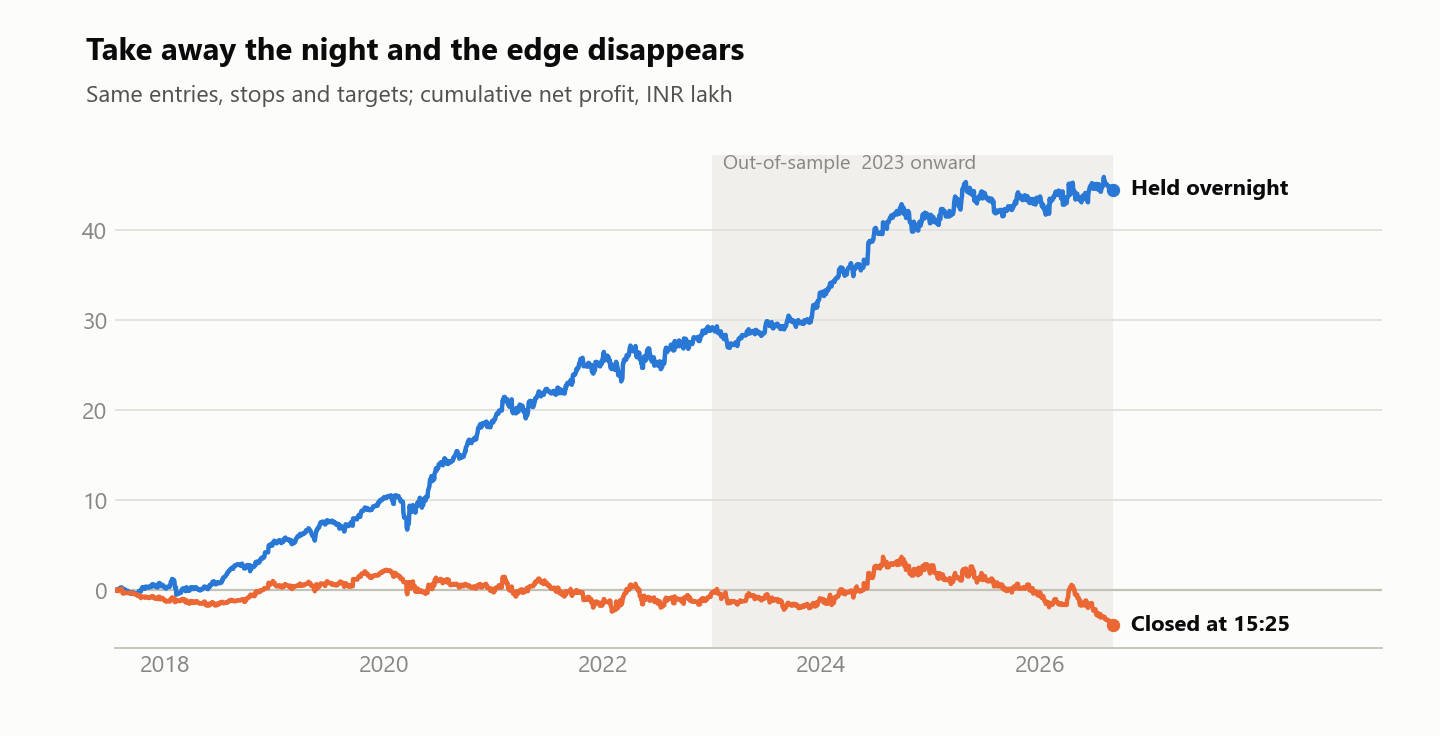

In [10]:
show('3-overnight-vs-same-day')

## 4. Remove the breakout

Buy at 15:25 and sell at 09:45 with no stop or target, either on **every** night or only on nights when the system was holding a position at 15:25.

In [11]:
EVERY, CHOSEN = 'Every night, 15:25 to 09:45', 'Only system nights, 15:25 to 09:45'
rows = []
for p in ['IS', 'OOS']:
    d, n = daily[daily.period == p], nights[nights.period == p]
    for label, col, chosen in [('Every night', EVERY, n), ('Only the system\'s nights', CHOSEN, n[n.selected])]:
        rows.append(dict(period=p, nights=label, count=len(chosen), net_lakh=d[col].sum() * LAKH,
                         sharpe=sharpe(d[col]), avg_points=chosen.clock0945_net.mean(),
                         max_dd_lakh=max_drawdown(d[col]) * LAKH))
pd.DataFrame(rows)

,period,nights,count,net_lakh,sharpe,avg_points,max_dd_lakh
0,IS,Every night,1295,17.63,0.90,5.23,6.59
1,IS,Only the system's nights,598,21.13,1.64,13.59,3.10
2,OOS,Every night,900,2.91,0.16,1.25,8.83
3,OOS,Only the system's nights,428,16.00,1.33,14.38,2.12


In [12]:
# Average overnight gap (close to next 09:15 open), system's nights vs the rest
nights.groupby(['period', 'selected']).gap_points.mean().unstack().rename(columns={True: 'system nights', False: 'other nights'})

selected,other nights,system nights
period,,
IS,12.41,23.08
OOS,-0.60,30.68


**Could random nights do as well?** This reruns the study's tests: a 10-night block bootstrap for the difference, and 5,000 random picks of the same number of nights within each year-and-weekday group. With the same seed it reproduces the stored results exactly.

In [13]:
tests = {p: orb.selection_tests(nights[nights.period == p].reset_index(drop=True), ['gap_points', 'clock0945_net'])
         for p in ['IS', 'OOS']}
pd.DataFrame([dict(period=p, measure=k, difference=v['difference'], ci95_low=v['ci95'][0], ci95_high=v['ci95'][1],
                   random_picks_as_good=v['shuffles_at_least_as_good'], of=tests[p]['draws'])
              for p in tests for k, v in tests[p]['tests'].items()])

,period,measure,difference,ci95_low,ci95_high,random_picks_as_good,of
0,IS,gap_points,10.66,2.91,18.81,29,5000
1,IS,clock0945_net,15.52,6.68,24.41,0,5000
2,OOS,gap_points,31.28,17.31,46.01,0,5000
3,OOS,clock0945_net,25.04,11.21,39.25,3,5000


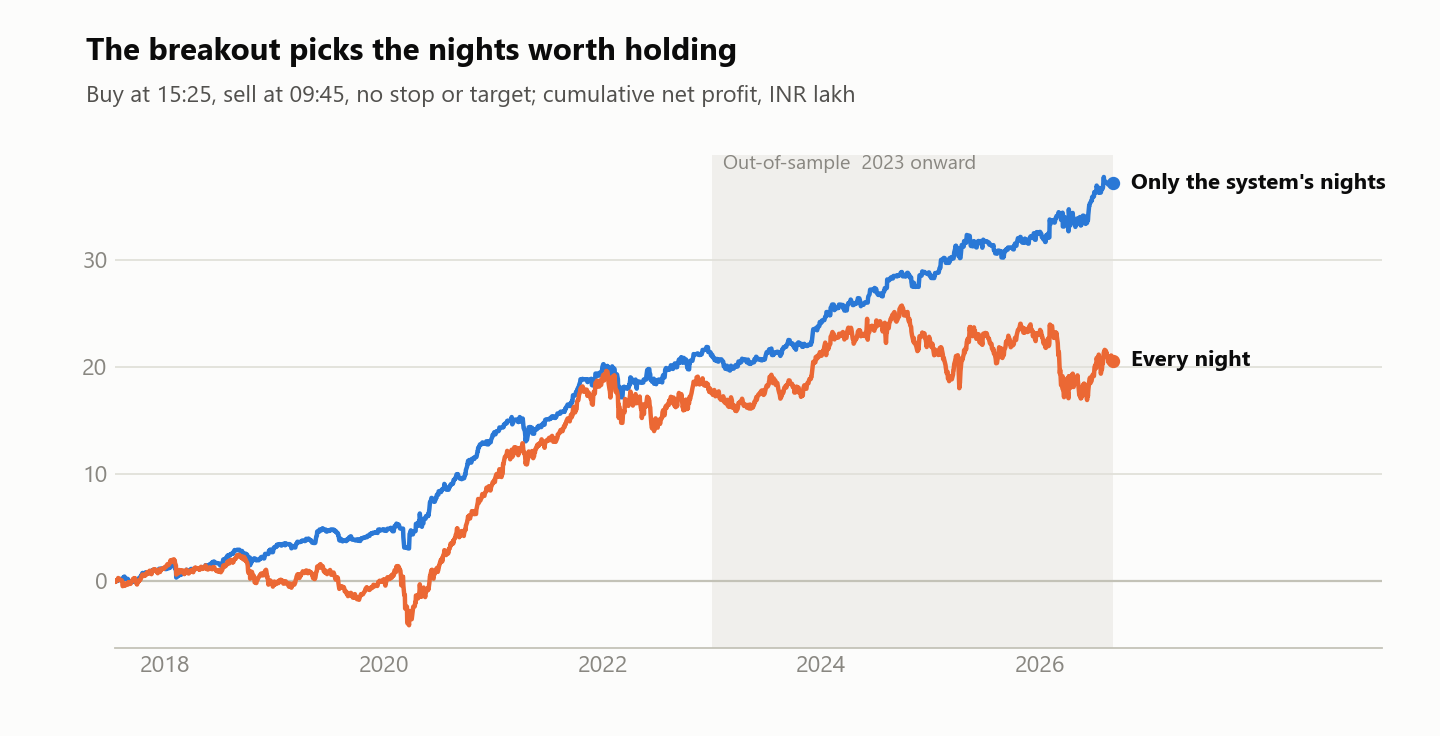

In [14]:
show('4-which-nights')

## 5. Move the exit clock

Exploratory: the same system with only the next-morning exit time changed. The history is split into two halves of equal length.

In [15]:
clocks = list(orb.EXIT_CLOCKS)
half = clock_daily.half
table = pd.DataFrame({c: {'full net': clock_daily[c].sum() * LAKH,
                          'Sharpe': sharpe(clock_daily[c]),
                          'first half': clock_daily.loc[half == 'First half', c].sum() * LAKH,
                          'second half': clock_daily.loc[half == 'Second half', c].sum() * LAKH} for c in clocks}).T
table['vs 09:45'] = table['full net'] - table.loc['09:45', 'full net']
table['given back after the open'] = clock_parts.set_index('clock').after_open * LAKH
table

,full net,Sharpe,first half,second half,vs 09:45,given back after the open
09:15,59.31,1.87,27.99,31.32,14.81,0.00
09:16,46.39,1.46,21.77,24.62,1.90,-12.91
09:17,48.09,1.50,21.98,26.10,3.59,-11.22
09:20,50.50,1.58,25.77,24.73,6.01,-8.80
09:22,51.17,1.59,27.05,24.11,6.67,-8.14
09:25,54.64,1.69,29.15,25.49,10.14,-4.67
09:30,50.24,1.55,27.55,22.69,5.75,-9.06
09:45,44.50,1.35,24.08,20.41,0.00,-14.81
10:00,39.61,1.23,21.87,17.74,-4.88,-16.41


In [16]:
# 09:25 against 09:45, in each half separately
(table.loc['09:25', ['first half', 'second half']] - table.loc['09:45', ['first half', 'second half']]).rename('09:25 minus 09:45, INR lakh')

first half    5.07
second half   5.08
Name: 09:25 minus 09:45, INR lakh, dtype: float64

In [17]:
# Captured overnight gap is identical for every clock from 09:15 to 09:45; only the giveback differs
(clock_parts.set_index('clock').captured_gap * LAKH).round(2)

clock
09:15   64.23
09:16   64.23
09:17   64.23
09:20   64.23
09:22   64.23
09:25   64.23
09:30   64.23
09:45   64.23
10:00   61.06
Name: captured_gap, dtype: float64

In [18]:
# Paired block bootstrap of the daily difference, 09:25 minus 09:45 (same method and seed as the study)
rng = np.random.default_rng(211026)
n = len(clock_daily)
starts = rng.integers(n, size=(5000, int(np.ceil(n / 10))))
ix = ((starts[:, :, None] + np.arange(10)) % n).reshape(5000, -1)[:, :n]
delta = (clock_daily['09:25'] - clock_daily['09:45']).to_numpy()
print('95% interval, points per day:', np.percentile(delta[ix].mean(axis=1), [2.5, 97.5]).round(2))

95% interval, points per day: [0.92 2.59]


**Try it yourself:** set `clock` to any exit time to compare its year-by-year profit with 09:45.

In [19]:
clock = '09:25'
by_year = clock_daily.groupby(clock_daily.date.dt.year)[[clock, '09:45']].sum() * LAKH
by_year['difference'] = by_year[clock] - by_year['09:45']
by_year

,09:25,09:45,difference
date,,,
2017,0.42,0.29,0.13
2018,6.45,5.20,1.25
2019,6.29,4.74,1.55
2020,8.29,8.39,-0.10
2021,7.70,6.86,0.84
2022,7.61,3.61,4.00
2023,5.12,3.84,1.27
2024,9.19,7.99,1.21
2025,2.53,2.54,-0.01


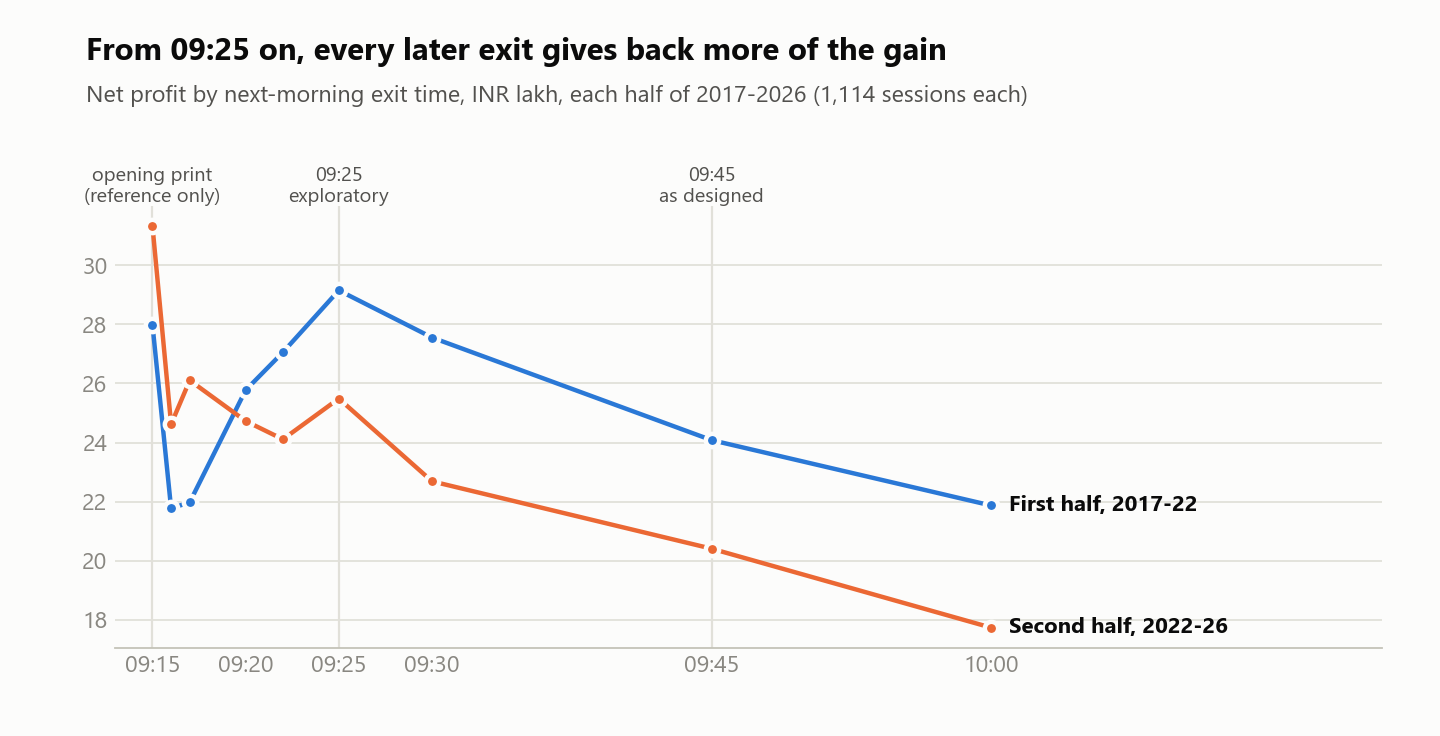

In [20]:
show('5-exit-clocks')

## 6. The phenomenon in the whole index

Nifty 50's own moves, split into overnight (previous close to the 09:15 open) and trading hours (09:15 open to close), in basis points. No system involved.

In [21]:
night, day = index.overnight_bps.dropna(), index.daytime_bps
phenomenon = pd.DataFrame({
    'overnight': {'count': len(night), 'share up %': (night > 0).mean() * 100, 'average bp': night.mean(),
                  'std dev bp': night.std(), 'compounded %': (np.exp(night.sum() / 1e4) - 1) * 100},
    'trading hours': {'count': len(day), 'share up %': (day > 0).mean() * 100, 'average bp': day.mean(),
                      'std dev bp': day.std(), 'compounded %': (np.exp(day.sum() / 1e4) - 1) * 100}})
phenomenon

,overnight,trading hours
count,"2,196.00","2,228.00"
share up %,65.12,47.76
average bp,10.85,-6.47
std dev bp,60.58,81.81
compounded %,983.79,-76.36


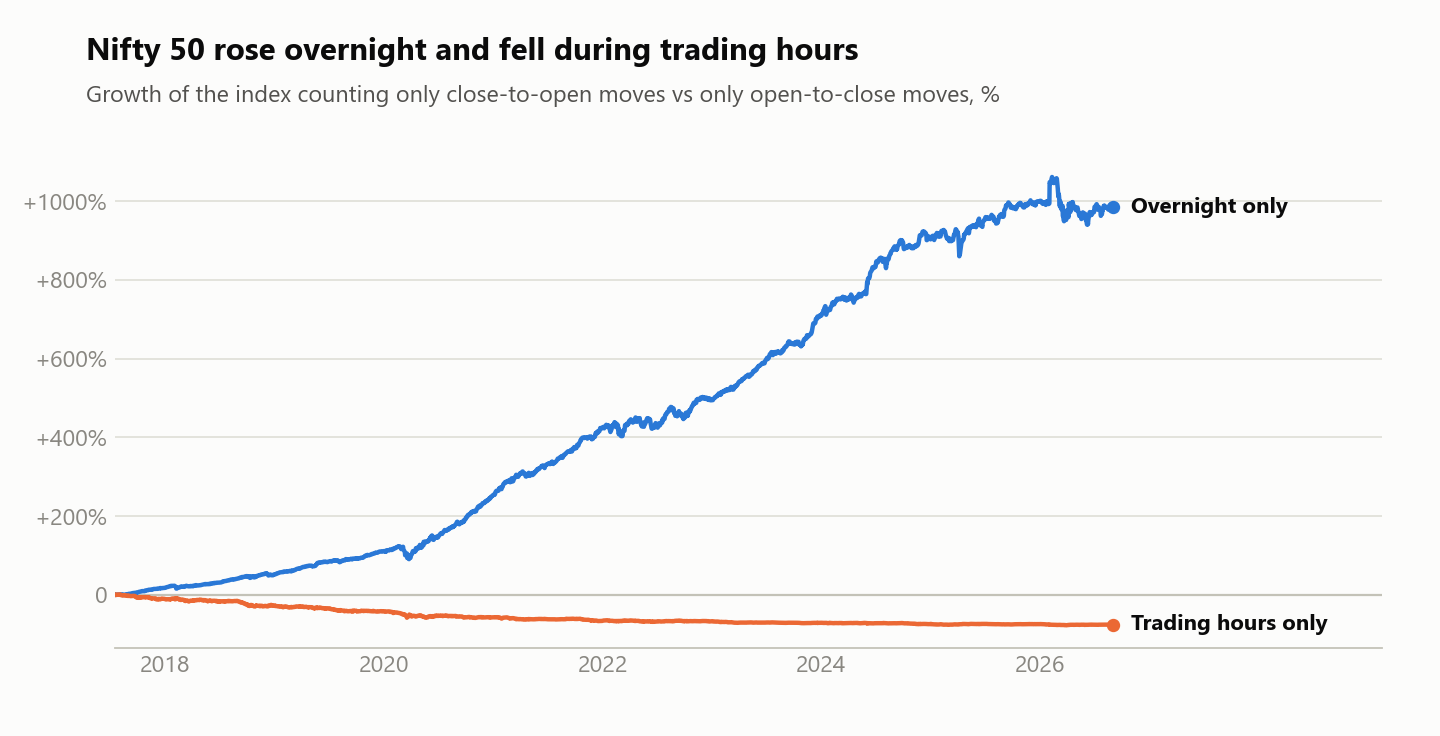

In [22]:
show('6-nifty-overnight-vs-daytime')

## 7. The recent period: October 2024 onward

The Nifty fell and moved sideways from late 2024. Here: what happened to the drift, to the system's night selection, and to its results.

In [23]:
recent_index = index.date >= '2024-10-01'
drift = pd.DataFrame({label: {'average overnight bp': index.loc[m, 'overnight_bps'].mean(),
                              'share of nights up %': (index.loc[m, 'overnight_bps'].dropna() > 0).mean() * 100}
                      for label, m in [('before Oct 2024', ~recent_index), ('since Oct 2024', recent_index)]})
drift

,before Oct 2024,since Oct 2024
average overnight bp,13.36,1.77
share of nights up %,68.27,53.68


In [24]:
recent_nights = nights.date >= '2024-10-01'
nights[recent_nights].groupby('selected').gap_points.mean().rename({True: 'system nights', False: 'other nights'})

selected
other nights    -16.64
system nights    29.61
Name: gap_points, dtype: float64

In [25]:
pnl = daily[SYSTEM] * LAKH
recent = daily.date >= '2024-10-01'
span = int(recent.sum())
windows = pnl.rolling(span).sum()
earlier = windows[daily.date.shift(span - 1) < '2024-09-26']   # windows that start before this stretch
equity = pnl.cumsum()
dd = equity.cummax() - equity
print(f'Net since October 2024: INR {pnl[recent].sum():.2f} lakh over {span} sessions')
print(f'Earlier {span}-session windows earning as little: {(earlier <= pnl[recent].sum()).sum()} of {earlier.notna().sum()}')
print(f'Deepest drawdown since Oct 2024: INR {dd[recent].max():.2f} lakh (trough {daily.date[dd[recent].idxmax()].date()})')
print(f'All-time deepest: INR {dd.max():.2f} lakh (trough {daily.date[dd.idxmax()].date()})')
print(f'Latest equity high: {daily.date[equity.idxmax()].date()}')
pnl.groupby(daily.date.dt.year).sum().loc[2024:]

Net since October 2024: INR 1.99 lakh over 476 sessions
Earlier 476-session windows earning as little: 0 of 1749
Deepest drawdown since Oct 2024: INR 3.80 lakh (trough 2025-08-29)
All-time deepest: INR 3.82 lakh (trough 2020-03-19)
Latest equity high: 2026-08-03


date
2024   7.99
2025   2.54
2026   1.03
Name: System (exit 09:45 next day), dtype: float64

## Summary

- The system's profit is the overnight gap. The entry day barely covers costs, and the next morning gives part of the gap back.
- Holding the same trades only until 15:25 loses money. Holding every night earns a little. Holding the nights the breakout picks earns most of the system's profit, with a third of the drawdown.
- From 09:25 onward, every later exit gives back more of the gain, in both halves of the history. Alternative exit times are exploratory.
- The Nifty 50 itself rose overnight and fell during trading hours: the overnight drift.